In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)

print("GPU Available:",
      tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.4.6


In [3]:
fashion_mnist = tf.keras.datasets.fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


In [6]:
class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]

for i, name in enumerate(class_names):
    print(i, ":", name)

0 : T-shirt/top
1 : Trouser
2 : Pullover
3 : Dress
4 : Coat
5 : Sandal
6 : Shirt
7 : Sneaker
8 : Bag
9 : Ankle boot


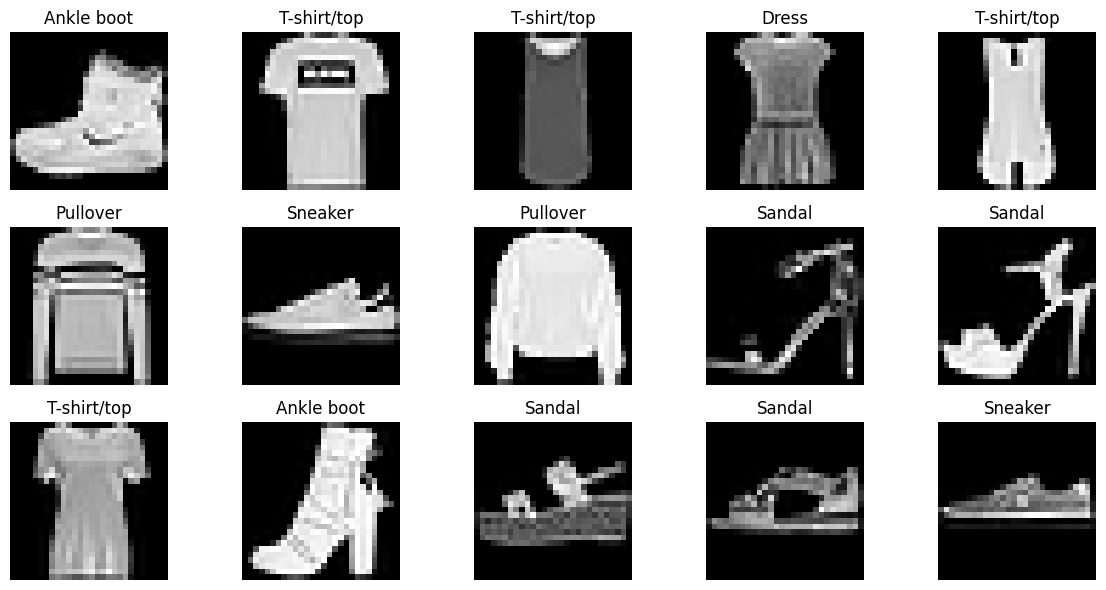

In [7]:
plt.figure(figsize=(12, 6))

for i in range(15):

    plt.subplot(3, 5, i + 1)

    plt.imshow(X_train[i], cmap='gray')

    plt.title(class_names[y_train[i]])

    plt.axis('off')

plt.tight_layout()
plt.show()

In [8]:
print("Image Shape:", X_train[0].shape)

print("Pixel Values:")
print(X_train[0])

print("Minimum Pixel:", X_train[0].min())
print("Maximum Pixel:", X_train[0].max())

Image Shape: (28, 28)
Pixel Values:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   

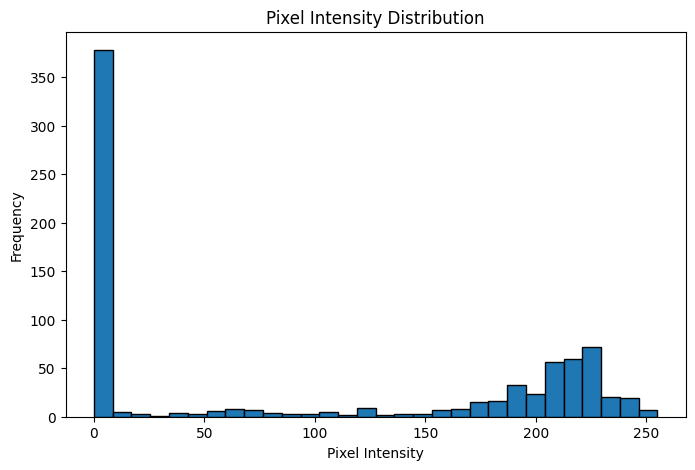

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(
    X_train[0].flatten(),
    bins=30,
    edgecolor='black'
)

plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.show()

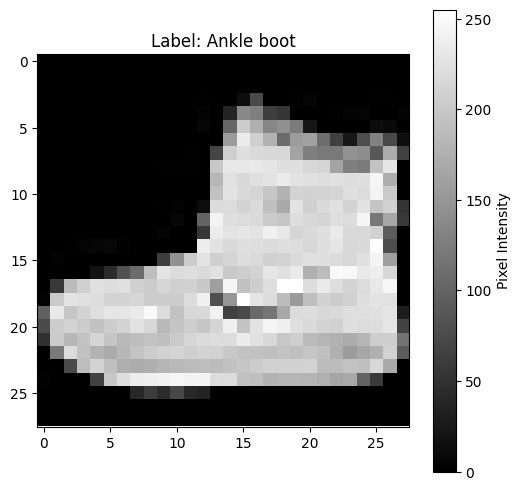

In [10]:
plt.figure(figsize=(6, 6))

plt.imshow(X_train[0], cmap='gray')

plt.colorbar(label='Pixel Intensity')

plt.title(
    f"Label: {class_names[y_train[0]]}"
)

plt.show()

In [11]:
unique, counts = np.unique(
    y_train,
    return_counts=True
)

for label, count in zip(unique, counts):

    print(
        class_names[label],
        ":",
        count
    )

T-shirt/top : 6000
Trouser : 6000
Pullover : 6000
Dress : 6000
Coat : 6000
Sandal : 6000
Shirt : 6000
Sneaker : 6000
Bag : 6000
Ankle boot : 6000


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.1667,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (49998, 28, 28)
Validation: (10002, 28, 28)
Testing: (10000, 28, 28)


In [13]:
X_train = X_train.astype('float32') / 255.0

X_val = X_val.astype('float32') / 255.0

X_test = X_test.astype('float32') / 255.0

In [14]:
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

print("Data Type:", X_train.dtype)

Minimum: 0.0
Maximum: 1.0
Data Type: float32


In [ ]:

X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

In [24]:
print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (49998, 28, 28, 1, 1)
Validation Shape: (10002, 28, 28, 1, 1)
Testing Shape: (10000, 28, 28, 1, 1)


In [27]:
X_train = np.squeeze(X_train, axis=-1)
X_val = np.squeeze(X_val, axis=-1)
X_test = np.squeeze(X_test, axis=-1)


In [28]:
print("Training Data")
print("Shape:", X_train.shape)
print("Min:", X_train.min())
print("Max:", X_train.max())

print("\nValidation Data")
print("Shape:", X_val.shape)

print("\nTesting Data")
print("Shape:", X_test.shape)

Training Data
Shape: (49998, 28, 28, 1)
Min: 0.0
Max: 1.0

Validation Data
Shape: (10002, 28, 28, 1)

Testing Data
Shape: (10000, 28, 28, 1)


In [29]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (49998, 28, 28, 1)
Validation: (10002, 28, 28, 1)
Testing: (10000, 28, 28, 1)


In [30]:
model = tf.keras.Sequential([
    # Input layer
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # First convolution block
    tf.keras.layers.Conv2D(
        32, (3, 3), activation='relu'
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second convolution block
    tf.keras.layers.Conv2D(
        64, (3, 3), activation='relu'
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),

    # Output layer
    tf.keras.layers.Dense(10, activation='softmax')
])

In [31]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [33]:
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val)
)

Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.7927 - loss: 0.5694 - val_accuracy: 0.8617 - val_loss: 0.3758
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8645 - loss: 0.3747 - val_accuracy: 0.8847 - val_loss: 0.3152
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8816 - loss: 0.3257 - val_accuracy: 0.8947 - val_loss: 0.2856
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8923 - loss: 0.2952 - val_accuracy: 0.9015 - val_loss: 0.2669
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8999 - loss: 0.2719 - val_accuracy: 0.9001 - val_loss: 0.2680
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9069 - loss: 0.2521 - val_accuracy: 0.9078 - val_loss: 0.2517
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9139 - loss: 0.2335 - val_accuracy: 0.9152 - val_loss: 0.2321
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9188 - loss: 0.2185 - val_accuracy: 

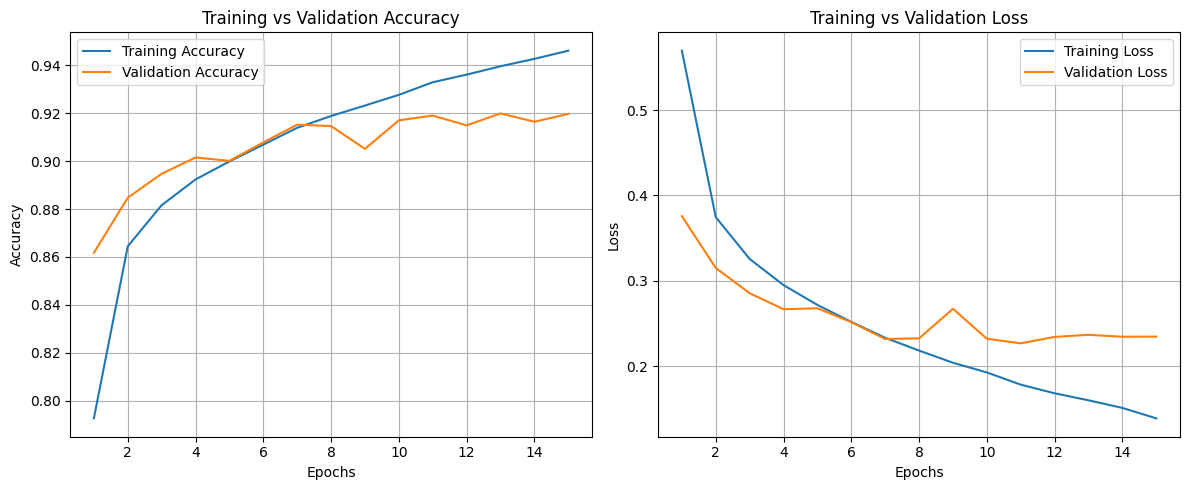

In [34]:
import matplotlib.pyplot as plt

# Extract training history
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

train_loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(train_acc) + 1)

# Accuracy graph
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_acc, label='Training Accuracy')
plt.plot(epochs, val_acc, label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(epochs, train_loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [35]:
# Evaluate model on test dataset
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9152 - loss: 0.2618
Test Loss: 0.2617502808570862
Test Accuracy: 91.51999950408936 %


In [36]:
import numpy as np
from sklearn.metrics import classification_report

# Generate predictions
y_pred_prob = model.predict(X_test)

# Convert probabilities into predicted class labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Classification report
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.89      0.87      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.84      0.90      0.87      1000
       Dress       0.91      0.92      0.92      1000
        Coat       0.86      0.87      0.87      1000
      Sandal       0.98      0.99      0.98      1000
       Shirt       0.80      0.70      0.75      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.99      0.98      0.98      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.91      0.92      0.91     10000
weighted avg       0.91      0.92      0.91     10000



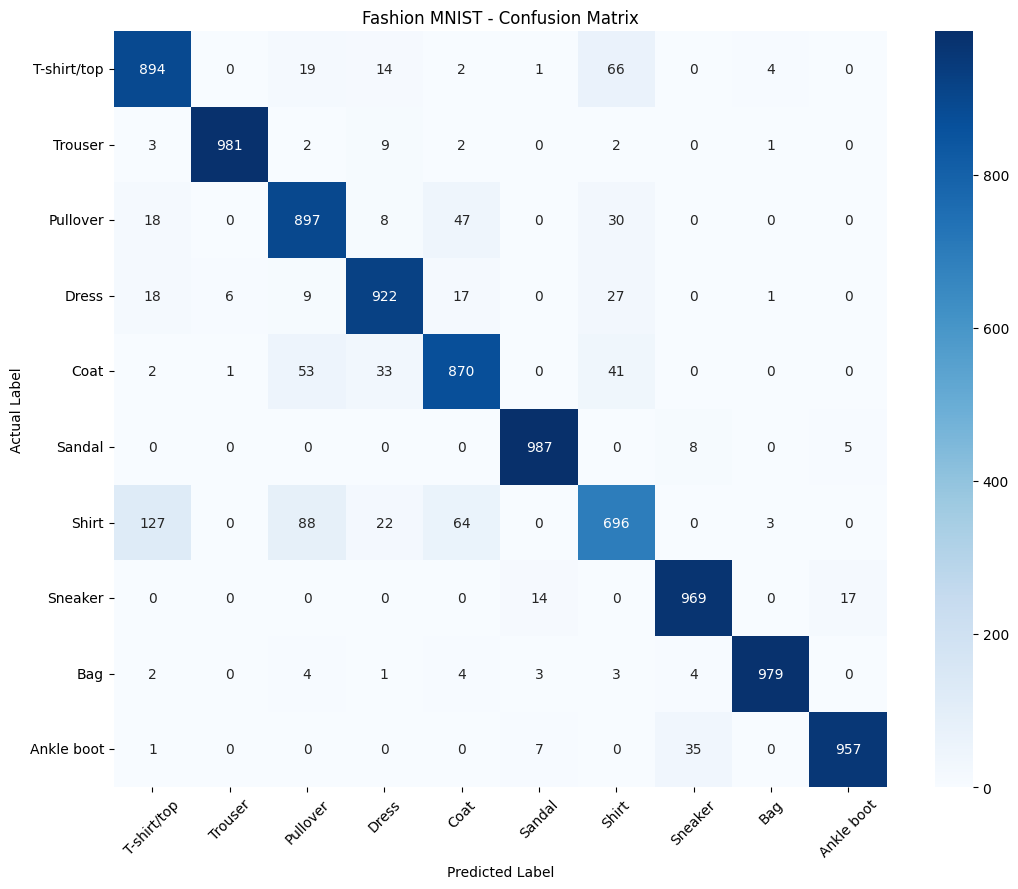

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Fashion MNIST - Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [38]:
model.save("fashion_mnist_cnn.keras")

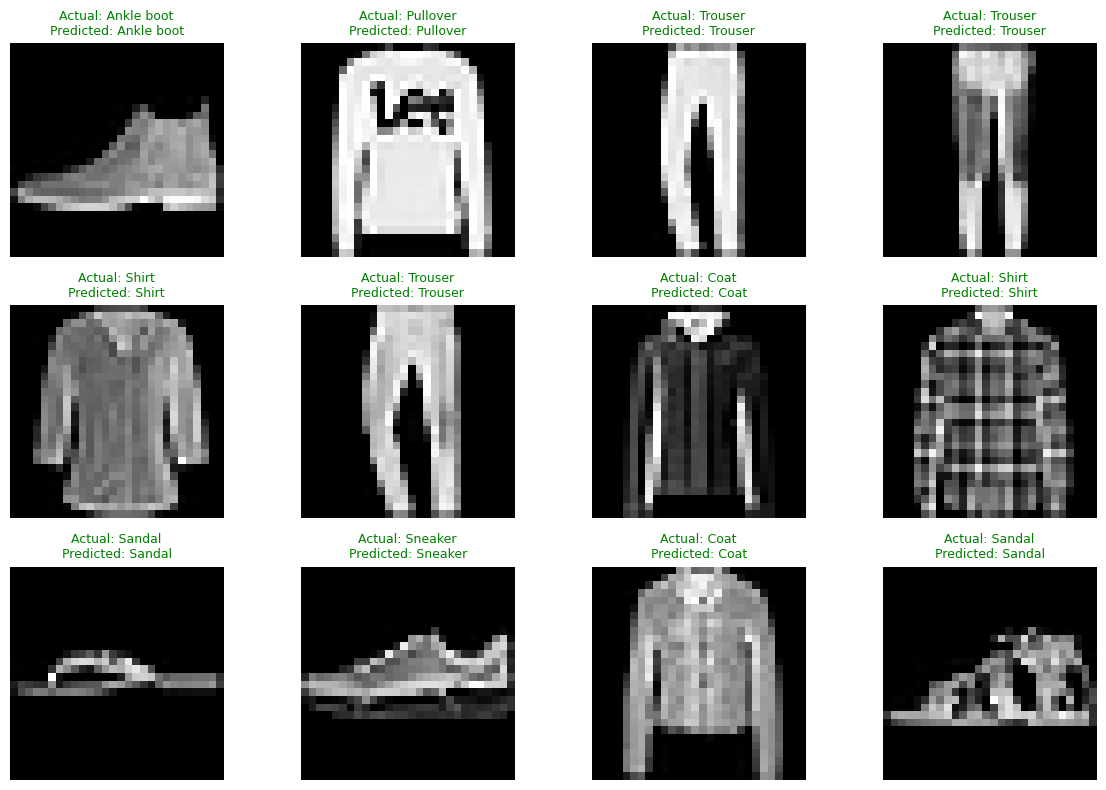

In [39]:
plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(X_test[i].squeeze(), cmap='gray')

    actual = class_names[y_test[i]]
    predicted = class_names[y_pred[i]]

    color = 'green' if actual == predicted else 'red'

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.tight_layout()
plt.show()